# RQ08 — Evolução temporal da frequência de releases (#175)

**Escolha registrada:** evolução temporal, em vez de rework rate. Pergunta exploratória: como varia a frequência mensal de releases estáveis nos projetos já existentes no início da janela?

As definições foram fixadas nesta análise, após a coleta; não se trata de hipótese pré-registrada. Não são necessárias novas consultas ao GitHub, tokens, commits ou runs. O notebook lê somente o CSV final e a tabela de IDs/datas de releases publicada em `dados/rq08_releases.csv`, com seu manifesto. O método e a exportação estão em `pipeline/evolucao_temporal.py`.

## Reprodução e população

Instale `requirements.txt` e execute todas as células a partir de `Lab03/` ou `Lab03/analise/`. Para entradas alternativas, defina `LAB03_RQ08_EVENTOS` (CSV acompanhado do JSON de proveniência) e `LAB03_RQ08_DATASET` (CSV acompanhado de `manifesto.csv.json`). `LAB03_RQ08_SAIDA` altera a pasta que receberá `tabelas/` e `figuras/`. Caminhos relativos são resolvidos a partir da pasta de trabalho.

O manifesto e as contagens por ID são conferidos contra a frequência anual do CSV. A análise principal é um painel fixo de projetos criados **até o início da janela**: projetos criados depois são excluídos, para não receberem zeros antes de existir. A sensibilidade usa o mesmo painel sem indicadores gerais de coleta incompleta ou cálculo parcial. Esses indicadores não são específicos de releases.

Cada projeto recebe uma linha por mês, inclusive zero quando não há publicação registrada. A taxa é `contagem / (dias reais do mês / 7)`. Os quartis usam interpolação linear. Dois semestres são comparados pelo mesmo conjunto de IDs, normalizados por suas durações reais; a diferença pareada é a taxa do segundo menos a do primeiro.

In [1]:
import os
from pathlib import Path
import sys

candidatas = [Path.cwd(), Path.cwd().parent, Path.cwd() / "Lab03"]
raiz = next(p.resolve() for p in candidatas if (p / "pipeline/evolucao_temporal.py").is_file())
sys.path.insert(0, str(raiz))
os.environ.setdefault("MPLCONFIGDIR", str(raiz / "data/processed/matplotlib-rq08"))
from IPython.display import display, Markdown
from pipeline.evolucao_temporal import executar, figura

eventos = Path(os.environ.get("LAB03_RQ08_EVENTOS", raiz / "analise/dados/rq08_releases.csv"))
dataset = Path(os.environ.get("LAB03_RQ08_DATASET", raiz / "entregas/s02-03-dataset-500-final/dataset-500.csv"))
saida = Path(os.environ.get("LAB03_RQ08_SAIDA", raiz / "analise"))
painel, mensal, semestres, proveniencia = executar(eventos, dataset, saida / "tabelas")
display(Markdown(f"**População: {proveniencia['populacao']}. Painel inicial: {proveniencia['painel_inicial']}. "
                 f"Excluídos por criação posterior: {proveniencia['criados_apos_inicio_excluidos']}. "
                 f"Painel sem alertas: {proveniencia['painel_sem_alertas']}.**"))
proveniencia

**População: 500. Painel inicial: 429. Excluídos por criação posterior: 71. Painel sem alertas: 398.**

{'escolha': 'evolucao_temporal',
 'dataset_sha256': '2552ba6b0779e895d01bea88742cb668ee1812a8369a224ed5281708140b30bd',
 'eventos_sha256': '569914771958ab8c2f882ec1dd2f12e01405e833888c716bc3d4d0a958187131',
 'janela': {'inicio': '2025-10-01T00:00:00Z',
  'fim_exclusivo': '2026-10-01T00:00:00Z'},
 'populacao': 500,
 'painel_inicial': 429,
 'criados_apos_inicio_excluidos': 71,
 'painel_sem_alertas': 398,
 'metodo': 'Releases estáveis por semana real do mês; painel fixo; quartis lineares. Semestres pareados por ID com exposição real; análise descritiva, sem teste de tendência.',
 'limites': 'Seleção retrospectiva por popularidade e >=5 releases anuais; não representa todos os projetos. Um ciclo anual não demonstra sazonalidade ou causalidade. Zero observado não prova ausência de publicações omitidas pela fonte. Alertas de qualidade são gerais, não específicos de releases.'}

## Distribuição mensal

Mediana, Q1 e Q3 são calculados entre projetos, incluindo os meses com zero registrado. A média é mostrada para evidenciar a influência dos projetos que publicam muitas releases. Não se usam meses de quatro semanas nem contagens brutas para comparar meses com durações diferentes.

In [2]:
display(mensal.round(4))

,coorte,mes,dias,n,releases,ativos,mediana,q1,q3,media
0,painel_inicial,2025-10,31.0,429,1967,312,0.4516,0.0000,0.9032,1.0353
1,painel_inicial,2025-11,30.0,429,1956,312,0.2333,0.0000,0.9333,1.0639
2,painel_inicial,2025-12,31.0,429,1922,303,0.2258,0.0000,0.9032,1.0117
3,painel_inicial,2026-01,31.0,429,2009,309,0.4516,0.0000,0.9032,1.0574
4,painel_inicial,2026-02,28.0,429,1808,314,0.2500,0.0000,1.0000,1.0536
5,painel_inicial,2026-03,31.0,429,2303,338,0.4516,0.2258,1.1290,1.2122
6,painel_inicial,2026-04,30.0,429,2453,326,0.4667,0.2333,0.9333,1.3342
7,painel_inicial,2026-05,31.0,429,2298,320,0.4516,0.0000,0.9032,1.2096
8,painel_inicial,2026-06,30.0,429,2313,327,0.4667,0.2333,0.9333,1.2580
9,painel_inicial,2026-07,31.0,429,2572,331,0.4516,0.2258,0.9032,1.3538


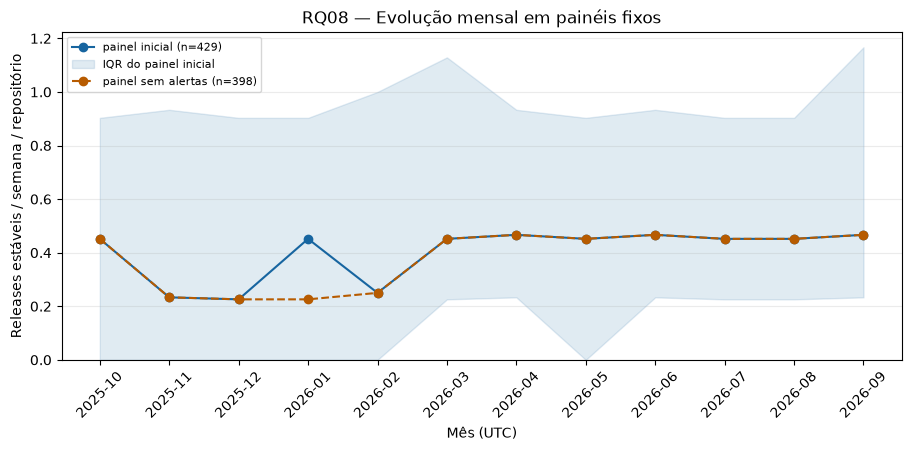

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
fig = figura(mensal, saida / "figuras/rq08_evolucao_mensal.png")
display(fig)
plt.close(fig)

## Primeiro e segundo semestres

A taxa semestral é a soma de releases dividida pelas semanas reais daquele semestre, não a média simples das taxas mensais. A mediana da diferença é calculada sobre diferenças por ID; ela não precisa ser igual à diferença entre as duas medianas. As contagens de aumento e diminuição descrevem taxas, não fazem teste estatístico. Mesmo contagens iguais podem dar taxas ligeiramente distintas quando a exposição difere.

In [4]:
display(semestres.round(6))
for r in semestres.to_dict("records"):
    display(Markdown(f"**{r['coorte']} (n={r['n']}):** mediana de {r['mediana_primeiro']:.4f} "
                     f"para {r['mediana_segundo']:.4f} release/semana; mediana da diferença pareada "
                     f"{r['mediana_diferenca']:.4f}. Aumentaram: {r['aumentaram']}; diminuíram: "
                     f"{r['diminuiram']}; iguais: {r['iguais']}."))

,coorte,n,semanas_primeiro,semanas_segundo,mediana_primeiro,mediana_segundo,mediana_diferenca,aumentaram,diminuiram,iguais
0,painel_inicial,429,26.0,26.142857,0.384615,0.420765,0.036780,228,201,0
1,painel_sem_alertas,398,26.0,26.142857,0.346154,0.420765,0.036675,211,187,0


**painel_inicial (n=429):** mediana de 0.3846 para 0.4208 release/semana; mediana da diferença pareada 0.0368. Aumentaram: 228; diminuíram: 201; iguais: 0.

**painel_sem_alertas (n=398):** mediana de 0.3462 para 0.4208 release/semana; mediana da diferença pareada 0.0367. Aumentaram: 211; diminuíram: 187; iguais: 0.

## Interpretação e resumo para o artigo

Os resultados abaixo são gerados a partir das tabelas, mantendo a população e as exclusões explícitas. O texto descreve o período observado, sem concluir crescimento monotônico, sazonalidade ou efeitos causais.

In [5]:
principal = mensal[mensal["coorte"] == "painel_inicial"]
r = semestres.iloc[0]
s = semestres.iloc[1]
display(Markdown(
    f"No painel fixo de **{int(r['n'])}** projetos, as medianas mensais variaram de "
    f"**{principal['mediana'].min():.3f} a {principal['mediana'].max():.3f}** release/semana. "
    f"A mediana semestral passou de **{r['mediana_primeiro']:.3f} para {r['mediana_segundo']:.3f}**, "
    f"com diferença pareada mediana de **{r['mediana_diferenca']:.3f}**. "
    f"No painel sem alertas (n={int(s['n'])}), passou de {s['mediana_primeiro']:.3f} "
    f"para {s['mediana_segundo']:.3f}. A dispersão mensal e as diminuições individuais impedem "
    "interpretar a diferença entre semestres como crescimento uniforme dos projetos."))

No painel fixo de **429** projetos, as medianas mensais variaram de **0.226 a 0.467** release/semana. A mediana semestral passou de **0.385 para 0.421**, com diferença pareada mediana de **0.037**. No painel sem alertas (n=398), passou de 0.346 para 0.421. A dispersão mensal e as diminuições individuais impedem interpretar a diferença entre semestres como crescimento uniforme dos projetos.

## Limitações

- A seleção é retrospectiva: projetos populares e com pelo menos cinco releases anuais. O painel não representa todos os projetos e não é uma amostra prospectiva.
- O painel principal exclui projetos criados após o início. Não atribui ausência de releases a períodos anteriores à existência do projeto, mas também não descreve a evolução dos 71 projetos novos da população original.
- Releases aproximam deploys; não são incidentes ou implantações comprovadas em produção. Rework rate, lead time, CFR e recuperação temporal não foram calculados nesta RQ.
- Zero significa nenhuma release estável **registrada** naquele mês; a reconciliação com o CSV verifica consistência, não prova completude da API.
- A exclusão de alertas é uma sensibilidade conservadora, pois os alertas também podem decorrer de outras métricas. Ela não certifica os projetos restantes como livres de viés.
- Um único ciclo anual e a comparação descritiva dos semestres não demonstram sazonalidade, tendência estatística, causalidade ou melhoria DORA geral. Não se atribui significado estatístico à pequena diferença observada.

Arquivos gerados: `tabelas/rq08_painel_mensal.csv`, `rq08_mensal.csv`, `rq08_semestres.csv`, `rq08_proveniencia.json` e `figuras/rq08_evolucao_mensal.png`. A extração de datas pode ser refeita a partir de um `releases.json` local/restaurado com `python -m pipeline.evolucao_temporal --releases CAMINHO --eventos analise/dados/rq08_releases.csv`; esse comando não chama a API.